# 🛡️ Human-in-the-Loop (HITL) Workflow with LangGraph

> **Mastering Agentic Oversight, Approval Gates, and State Time-Travel in Production**

---

## 📌 Why Human-in-the-Loop (HITL) is Essential

Fully autonomous AI agents are powerful, but enterprise systems carry severe real-world consequences:
- **Financial Risk**: Processing high-value payments or payouts without sign-off.
- **Operational Risk**: Executing irreversible database migrations, dropping partitions, or modifying Kubernetes routing.
- **Compliance & Legal**: PII handling, contract execution, and regulatory GDPR disclosures.
- **Disambiguation**: Resolving edge cases where model confidence is borderline.

LangGraph solves this with **native first-class checkpointing** and the **`interrupt()`** pattern.

<div align="center">

![Human in the Loop Workflow](diagrams/6_human_in_the_loop.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef prepNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef pauseNode fill:#FDEDEC,stroke:#E74C3C,stroke-width:3px,color:#78281F,font-weight:bold;
    classDef humanNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109,font-weight:bold;
    classDef execNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Inbound Infrastructure Change]):::startNode --> Plan[1. AI SRE: Plan Terraform Change]:::prepNode
    Plan --> Guard[2. Automated Policy & Blast Radius Check]:::prepNode
    
    Guard --> Check{Blast Radius > Threshold?}
    Check -->|High Impact / Critical| Pause[3. interrupt: Execution Paused]:::pauseNode
    Check -->|Low Impact| Apply[4. Auto-Apply]:::execNode
    
    Pause -.->|Emits State & Thread ID| Human([Human SecOps Lead Review]):::humanNode
    Human -.->|Command resume: Approval / Edit| Resume[Resume Graph Execution]:::execNode
    
    Resume --> Apply
    Apply --> END([Audit Ledger & Deployment Complete]):::execNode
```
</details>



---
## ⚙️ 1. Environment Setup & Configuration

We initialize our LLM from the centralized `llm_config.py` module and import LangGraph's HITL primitives:
- `MemorySaver`: In-memory thread state checkpointer (in production, use `SqliteSaver` or Postgres).
- `interrupt`: Pauses execution mid-node and yields control to the runtime.
- `Command(resume=...)`: Injects external user decisions back into the interrupted node.



In [1]:
import os
from typing import Dict, List, Any, Optional, TypedDict
from pydantic import BaseModel, Field

# Centralized LLM configuration
from llm_config import get_llm, list_free_models

# LangGraph HITL components
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

from IPython.display import Image, display

# Initialize shared LLM instance
llm = get_llm()
print("[OK] LLM Initialized successfully")

def visualize_graph(compiled_graph):
    """Helper to display LangGraph architecture with graceful fallbacks."""
    try:
        display(Image(compiled_graph.get_graph().draw_mermaid_png()))
    except Exception:
        try:
            print(compiled_graph.get_graph().draw_ascii())
        except Exception:
            print(compiled_graph.get_graph().draw_mermaid())



[OK] LLM Initialized successfully


---
## 🏗️ 2. Production Scenario: Production Database Infrastructure Rollout Gate

### Workflow Architecture
1. **`plan_change` (AI Node)**: Ingests a requested schema migration or infrastructure change, analyzes blast radius, and prepares a deployment manifest.
2. **`automated_guardrails` (AI/Rule Node)**: Verifies rollback strategy and estimates downtime.
3. **`human_approval_gate` (HITL Gate)**: Pauses execution via `interrupt()` if the change touches critical tables or has potential data loss.
4. **`apply_deployment` (Execution Node)**: Applies change only after human approval is received and logged.



In [2]:
# --- State and Schema Definitions ---

class InfraProposal(BaseModel):
    service_name: str
    target_environment: str
    risk_level: str = Field(..., description="'LOW', 'MEDIUM', 'HIGH', or 'CRITICAL'")
    estimated_downtime_seconds: int
    migration_summary: str
    rollback_plan: str

class HITLDeploymentState(TypedDict):
    change_request: str
    proposal: Optional[Dict[str, Any]]
    policy_check_passed: bool
    human_approval: Optional[Dict[str, Any]]
    deployment_log: Optional[str]

def plan_change_node(state: HITLDeploymentState) -> Dict[str, Any]:
    """Step 1: AI drafts infrastructure migration proposal and evaluates risk."""
    prompt = (
        "You are a Staff Cloud Infrastructure Engineer. Analyze this infrastructure change request:\n"
        f"Request: {state['change_request']}\n\n"
        "Draft a structured migration proposal assessing risk level (LOW/MEDIUM/HIGH/CRITICAL) and rollback plan."
    )
    structured_llm = llm.with_structured_output(InfraProposal)
    proposal: InfraProposal = structured_llm.invoke(prompt)
    return {"proposal": proposal.dict()}

def automated_guardrails_node(state: HITLDeploymentState) -> Dict[str, Any]:
    """Step 2: Automated verification of rollback strategy."""
    proposal = state["proposal"]
    has_rollback = bool(proposal.get("rollback_plan", "").strip())
    return {"policy_check_passed": has_rollback}

def human_approval_gate_node(state: HITLDeploymentState) -> Dict[str, Any]:
    """Step 3: Pause execution using interrupt() for Human SRE review."""
    proposal = state["proposal"]
    
    # Halt graph execution and deliver payload to user
    human_decision = interrupt({
        "event": "PRODUCTION_ROLLOUT_AUTHORIZATION_REQUIRED",
        "service": proposal["service_name"],
        "target_env": proposal["target_environment"],
        "risk_level": proposal["risk_level"],
        "downtime_sec": proposal["estimated_downtime_seconds"],
        "rollback_summary": proposal["rollback_plan"][:120],
        "prompt": "Review proposal. Respond with decision: 'APPROVED' or 'REJECTED', approver name, and comments."
    })
    
    return {"human_approval": human_decision}

def apply_deployment_node(state: HITLDeploymentState) -> Dict[str, Any]:
    """Step 4: Execute deployment based on received human sign-off."""
    approval = state.get("human_approval", {})
    decision = approval.get("decision", "REJECTED")
    approver = approval.get("approver", "Unknown")
    comments = approval.get("comments", "None")
    
    if decision.upper() == "APPROVED":
        msg = f"[DEPLOYED] Successfully applied migration to {state['proposal']['service_name']} in {state['proposal']['target_environment']}. Authorized by {approver} ({comments})."
    else:
        msg = f"[CANCELLED] Rollout aborted. Rejected by {approver}. Reason: {comments}."
        
    return {"deployment_log": msg}



---
## 🔨 3. Compiling the Graph with State Checkpointing

Notice that we pass `checkpointer=MemorySaver()` to `compile()`. **A checkpointer is mandatory for Human-in-the-Loop workflows**, as LangGraph must persist the execution frame, node history, and variables while waiting for external human input.



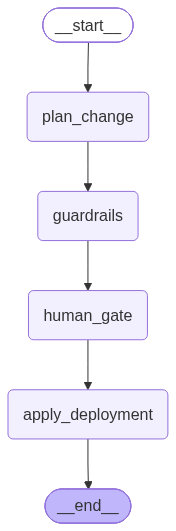

In [3]:
# Build and Compile StateGraph
hitl_builder = StateGraph(HITLDeploymentState)

hitl_builder.add_node("plan_change", plan_change_node)
hitl_builder.add_node("guardrails", automated_guardrails_node)
hitl_builder.add_node("human_gate", human_approval_gate_node)
hitl_builder.add_node("apply_deployment", apply_deployment_node)

hitl_builder.add_edge(START, "plan_change")
hitl_builder.add_edge("plan_change", "guardrails")
hitl_builder.add_edge("guardrails", "human_gate")
hitl_builder.add_edge("human_gate", "apply_deployment")
hitl_builder.add_edge("apply_deployment", END)

checkpointer = MemorySaver()
hitl_graph = hitl_builder.compile(checkpointer=checkpointer)

visualize_graph(hitl_graph)



---
## 🧪 4. Interactive Scenarios: Approval, Rejection, and State Inspection

### Scenario A: Full Approval Workflow
We start the workflow under a unique thread ID `thread-deploy-001`. It runs autonomously through `plan_change` and `guardrails`, then halts at `human_gate`.



In [4]:
# Scenario A: Starting the workflow
thread_a = {"configurable": {"thread_id": "thread-deploy-001"}}

request_a = {
    "change_request": "Upgrade Redis cache cluster from v6.2 to v7.2 in Production-US-East. Apply zero-downtime rolling node replacement.",
    "proposal": None,
    "policy_check_passed": False,
    "human_approval": None,
    "deployment_log": None
}

print("-> Starting execution for Thread A...")
run_a_pause = hitl_graph.invoke(request_a, config=thread_a)

# Inspect pause state
interrupt_payload = run_a_pause.get("__interrupt__")
print(f"-> Execution paused! Interrupt data:\n{interrupt_payload}\n")

# Inspect the graph state in the checkpointer
current_state = hitl_graph.get_state(thread_a)
print(f"Current next node to execute: {current_state.next}")
print(f"Risk assessed by AI: {current_state.values['proposal']['risk_level']}")



-> Starting execution for Thread A...
-> Execution paused! Interrupt data:
[Interrupt(value={'event': 'PRODUCTION_ROLLOUT_AUTHORIZATION_REQUIRED', 'service': 'redis-cache-cluster', 'target_env': 'Production-US-East', 'risk_level': 'MEDIUM', 'downtime_sec': 0, 'rollback_summary': "Pre-migration, each 6.2 node's RDB + AOF snapshot is retained on S3 (bucket: prod-us-east-redis-snapshots, lifecycle: 72", 'prompt': "Review proposal. Respond with decision: 'APPROVED' or 'REJECTED', approver name, and comments."}, id='24538a91542a0129978ac5fcc7961ac1')]

Current next node to execute: ('human_gate',)
Risk assessed by AI: MEDIUM


In [5]:
# Scenario A: Resuming execution with Human Approval
approval_payload = {
    "decision": "APPROVED",
    "approver": "Marcus Vance (Lead Cloud SRE)",
    "comments": "Maintenance window confirmed 02:00-03:00 UTC. Backup snapshot verified."
}

print("-> Resuming execution with Command(resume=...)...")
run_a_final = hitl_graph.invoke(
    Command(resume=approval_payload),
    config=thread_a
)

print("\n=== FINAL DEPLOYMENT RESULT ===")
print(run_a_final["deployment_log"])



-> Resuming execution with Command(resume=...)...

=== FINAL DEPLOYMENT RESULT ===
[DEPLOYED] Successfully applied migration to redis-cache-cluster in Production-US-East. Authorized by Marcus Vance (Lead Cloud SRE) (Maintenance window confirmed 02:00-03:00 UTC. Backup snapshot verified.).


---
### Scenario B: Human Rejection Workflow
In this scenario, a high-risk change (e.g. dropping a production table without backup) is caught and rejected by the human reviewer.



In [6]:
# Scenario B: Dangerous change rejected by human reviewer
thread_b = {"configurable": {"thread_id": "thread-deploy-002"}}

request_b = {
    "change_request": "Drop legacy analytics_events table (180M rows) directly in Production Aurora MySQL to reclaim disk space immediately.",
    "proposal": None,
    "policy_check_passed": False,
    "human_approval": None,
    "deployment_log": None
}

print("-> Starting execution for Thread B...")
run_b_pause = hitl_graph.invoke(request_b, config=thread_b)
print("-> Workflow paused at approval gate.")

# Rejection decision from Human SecOps
rejection_payload = {
    "decision": "REJECTED",
    "approver": "Elena Rostova (Head of Data Governance)",
    "comments": "Direct DROP TABLE forbidden in production. Must follow 30-day cold archive policy."
}

print("-> Resuming with Rejection Command...")
run_b_final = hitl_graph.invoke(
    Command(resume=rejection_payload),
    config=thread_b
)

print("\n=== REJECTION LOG ===")
print(run_b_final["deployment_log"])



-> Starting execution for Thread B...
-> Workflow paused at approval gate.
-> Resuming with Rejection Command...

=== REJECTION LOG ===
[CANCELLED] Rollout aborted. Rejected by Elena Rostova (Head of Data Governance). Reason: Direct DROP TABLE forbidden in production. Must follow 30-day cold archive policy..


---
## 🎯 Key Takeaways for Production HITL Systems

1. **State Persistence**: Always use a persistent checkpointer (e.g., `PostgresSaver` in production microservices) so graph execution can pause indefinitely across minutes, hours, or days while awaiting human response.
2. **Deterministic Payload Delivery**: The payload passed to `interrupt()` should contain all necessary context for a human to make an informed decision without needing to query multiple external systems.
3. **Audit Trail**: Always persist the human approver's identity, timestamp, and notes in the final state for regulatory and postmortem tracking.

